### MNIST dataset CNN example with synapx

The architecture of the MNIST CNN example of synapgrad. `Conv2d` and `MaxPool2d` use synapgrad's algorithm (sliding windows and tensordot) on top of libtorch, so the two projects can be compared. Set `engine_str` to `'synapx'` or `'torch'`.

In [1]:
import os
import sys
import torch
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets

# Import .././ directory
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

In [2]:
from examples.utils.data import split_dataset, DataLoader, DataLoaderCallback
from examples.utils.train import Trainer, Evaluator

In [3]:
supported_engines = ['synapx', 'torch']

In [4]:
seed = 42
engine_str = 'synapx'
device = 'cpu'

In [5]:
epochs = 5
batch_size = 128
lr = 0.01

In [6]:
if engine_str == 'synapx':
    import synapx as engine
    from synapx import nn, optim
elif engine_str == 'torch':
    import torch as engine
    from torch import nn, optim

torch.manual_seed(seed)
print("Engine:", engine_str)

Engine: synapx


Load dataset

In [7]:
train_set = datasets.MNIST('./mnist', train=True, download=True)
test_set = datasets.MNIST('./mnist', train=False, download=True)

trainX = train_set.data.numpy()
trainY = train_set.targets.numpy()
testX = test_set.data.numpy()
testY = test_set.targets.numpy()

(trainX, trainY), (valX, valY), _  = split_dataset(trainX, trainY, test_split=0.2)

# (N, 28, 28) -> (N, 1, 28, 28): one input channel
trainX = np.expand_dims(trainX / 255.0, axis=1)
valX = np.expand_dims(valX / 255.0, axis=1)
testX = np.expand_dims(testX / 255.0, axis=1)

assert 0 <= np.max(trainX) <= 1

# summarize loaded dataset
print('Train: X=%s, y=%s' % (trainX.shape, trainY.shape))
print('Val: X=%s, y=%s' % (valX.shape, valY.shape))
print('Test: X=%s, y=%s' % (testX.shape, testY.shape))

Train: X=(48000, 1, 28, 28), y=(48000,)
Val: X=(12000, 1, 28, 28), y=(12000,)
Test: X=(10000, 1, 28, 28), y=(10000,)


In [8]:
class Transform(DataLoaderCallback):
    
    def __call__(self, data_loader:'DataLoader', X_batch:np.ndarray, y_batch:np.ndarray): 
        x = engine.tensor(X_batch, dtype=torch.float32, device=device)
        y = engine.tensor(y_batch, dtype=torch.long, device=device)
        return x, y

transform_cb = Transform()

train_loader = DataLoader(trainX, trainY, batch_size, transform=transform_cb)
val_loader = DataLoader(valX, valY, batch_size=256, transform=transform_cb) # big batch size for val samples
test_loader = DataLoader(testX, testY, batch_size=256, transform=transform_cb) # big batch size for test samples

print("Train batches:", len(train_loader), "| Val batches:", len(val_loader), "| Test batches:", len(test_loader))

Train batches: 375 | Val batches: 46 | Test batches: 39


Plot a few training images

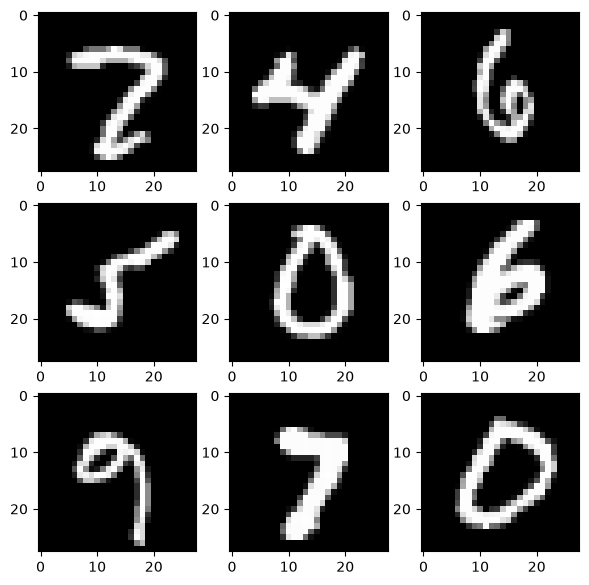

In [9]:
plt.figure(figsize=(7,7))
for i in range(9):
    plt.subplot(330 + 1 + i)
    plt.imshow(trainX[i].squeeze(), cmap=plt.get_cmap('gray'))
plt.show()

In [10]:
class CNN(nn.Module):

    def __init__(self):
        super().__init__()
        # 'same' padding keeps 28x28; each max pool halves it: 28 -> 14 -> 7
        conv1 = nn.Sequential(
            nn.Conv2d(1, 16, (3, 3), (1, 1), padding='same', bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.MaxPool2d(kernel_size=(2, 2))
        )
        conv2 = nn.Sequential(
            nn.Conv2d(16, 32, (3, 3), (1, 1), padding='same', bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.MaxPool2d(kernel_size=(2, 2))
        )
        self.cnn = nn.Sequential(conv1, conv2, nn.Flatten(), nn.Linear(32 * 7 * 7, 10))
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight)
            with engine.no_grad():
                module.weight *= 0.1  # make the logits layer less confident
            nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Conv2d):
            nn.init.kaiming_normal_(module.weight, nonlinearity='relu')

    def forward(self, x: engine.Tensor):
        return self.cnn(x)

model = CNN()
model.to(device)
print("CNN Model:", model)
print("CNN Trainable Parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

CNN Model: CNN(submodules=1, parameters=20538, trainable=20538, non_trainable=0)
CNN Trainable Parameters: 20538


In [11]:
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=lr)

trainer = Trainer(model, engine)
evaluator = Evaluator(accuracy=True, mode=Evaluator.MULTI_CLASS)
trainer.compile(loss_fn, optimizer, evaluator)
history = trainer.fit(train_loader, epochs=epochs, validation_loader=val_loader)

Epoch 1/5:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch 1/5: 100%|██████████| 375/375 [00:38<00:00,  9.62it/s, loss=0.2735, accuracy=0.9341, val_loss=0.1175, val_accuracy=0.9648]

Epoch 2/5:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch 2/5: 100%|██████████| 375/375 [00:39<00:00,  9.52it/s, loss=0.0742, accuracy=0.9769, val_loss=0.0775, val_accuracy=0.9808]

Epoch 3/5:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch 3/5: 100%|██████████| 375/375 [00:38<00:00,  9.75it/s, loss=0.0591, accuracy=0.9814, val_loss=0.0566, val_accuracy=0.9844]

Epoch 4/5:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch 4/5: 100%|██████████| 375/375 [00:38<00:00,  9.75it/s, loss=0.0499, accuracy=0.9846, val_loss=0.0575, val_accuracy=0.9841]

Epoch 5/5:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch 5/5: 100%|██████████| 375/375 [00:36<00:00, 10.28it/s, loss=0.0456, accuracy=0.9857, val_loss=0.0519, val_accuracy=0.9856]

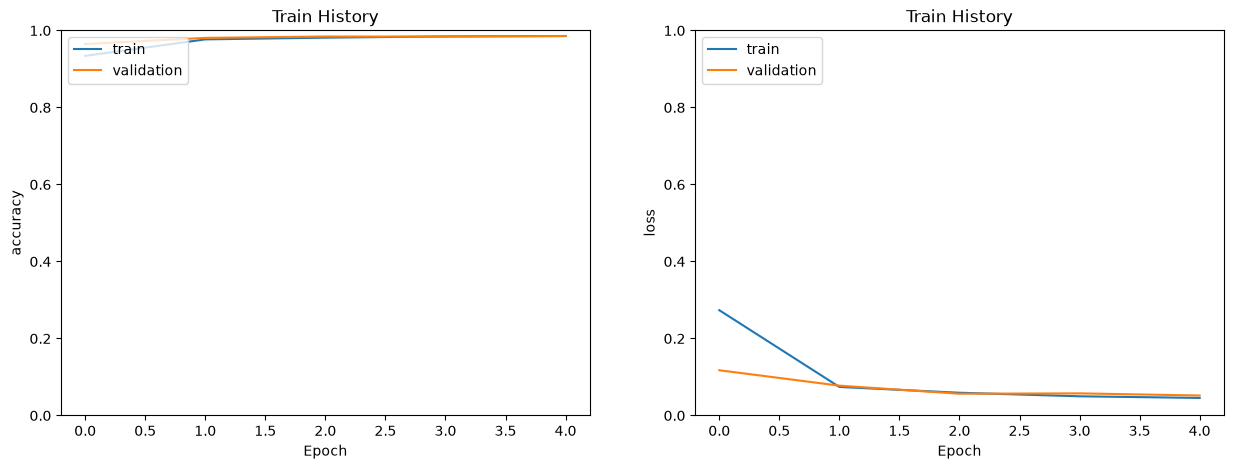

In [12]:
trainer.plot(['accuracy', 'loss'], ylim=[0, 1])

In [13]:
y_pred, y_true = trainer.test(test_loader)
evaluator.report(y_pred, y_true)

[INFO] Testing network...


Accuracy: 0.9861778846153846
[[ 974    0    1    0    0    0    2    1    1    0]
 [   0 1126    3    1    0    0    0    0    3    0]
 [   1    1 1023    2    0    0    1    2    0    0]
 [   1    0    5  996    0    3    0    1    2    0]
 [   0    0    2    0  969    0    4    0    2    3]
 [   1    0    0    5    0  881    1    0    1    1]
 [   3    2    1    0    1    2  945    0    2    0]
 [   0    2   15    0    2    0    0 1002    3    3]
 [   6    0    4    1    0    1    1    0  959    1]
 [   0    1    2    2    9    3    0    6   14  971]]
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       979
           1       0.99      0.99      0.99      1133
           2       0.97      0.99      0.98      1030
           3       0.99      0.99      0.99      1008
           4       0.99      0.99      0.99       980
           5       0.99      0.99      0.99       890
           6       0.99      0.99      0.99       956
       

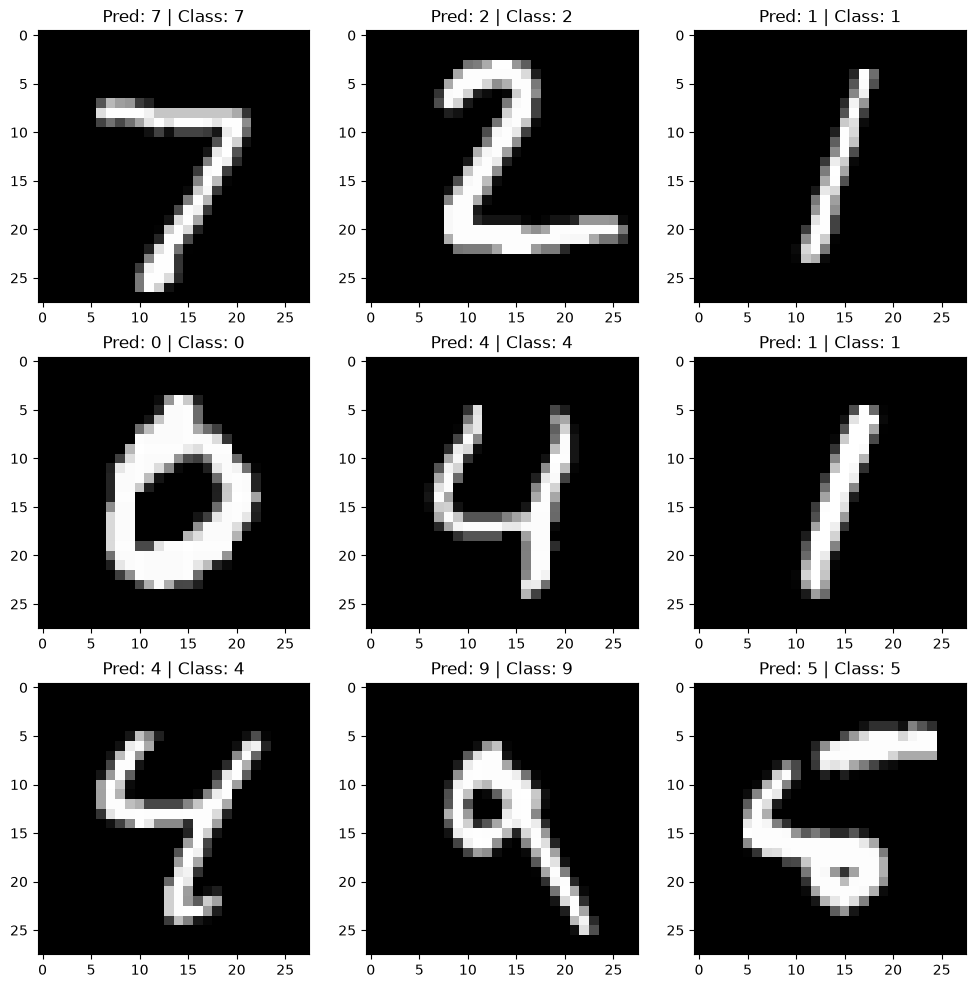

In [14]:
plt.figure(figsize=(12,12))
for i in range(9):
    plt.subplot(330 + 1 + i)
    plt.imshow(testX[i].squeeze(), cmap=plt.get_cmap('gray'))
    pred = y_pred[i].argmax(); label = y_true[i]
    plt.title(f"Pred: {pred} | Class: {label}")
plt.show()